# Machine Learning: Exercise session 06

In this exercise session we will focus on Logistic regression and decision trees.

In the first problem, we will consider the [ionosphere dataset](https://www.openml.org/d/59) and fit different logistic regression models.
The goal is to predict whether a given radar signal from the ionosphere is "good" or "bad" based on 34 predictors.

In the second problem, we will focus on decision trees.

In the third problem, we will derive the log-likelihood function for logistic regression.

**Note:** the third problem is theoretical and __not__ needed for the hand in.

## Problem 1

* Import the dataset `ionosphere.csv`, separate the predictors and the target variable and split it into training and test set. When you perform the splitting, set `random_state=12` and `test_size=151`.

In [2]:
import pandas as pd
data = pd.read_csv('ionosphere.csv')

* Define a `Pipeline` where you apply the `StandardScaler` and then fit a `LogisticRegression` with the following tuning parameters: `penalty="none"`, `solver="saga"`, `tol=0.1`, `random_state=10`. Call the pipeline `pipe_logistic`.

In [8]:
# pipeline with standard scaller and logistic regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe_logistic = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(penalty=None, solver='saga', tol=0.1, random_state=10))
])
#use data["class"] as target variable and the rest of the columns as features
pipe_logistic.fit(data.drop("class", axis=1), data["class"])


/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['b','g']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](34,)","['a01','a02','a03',...,'a32','a33','a34']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,34
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


* Fit the pipeline to the training data and predict the accuracy on the training and test dataset.

In [19]:
split = 0.8
#create train and test sets using the split variable
train = data.sample(frac=split, random_state=10)
test = data.drop(train.index)
X_train = train.drop("class", axis=1)
y_train = train["class"]
X_test = test.drop("class", axis=1)
y_test = test["class"]
#test acuacy of the model on the test set and train set
train_accuracy = pipe_logistic.score(train.drop("class", axis=1), train["class"])
test_accuracy = pipe_logistic.score(test.drop("class", axis=1), test["class"])

print(f"Train accuracy: {train_accuracy}")
print(f"Test accuracy: {test_accuracy}")

Train accuracy: 0.900355871886121
Test accuracy: 0.9


We now want to fit a logistic regression with the lasso penalty. To do that we need to choose the best regulatization parameter. 

* Define a `Kfold` object with 10 splits, and `random_state=919`. Remeber to shuffle the rows. Name the object `folds`.

In [12]:
#We now want to fit a logistic regression with the lasso penalty. To do that we need to choose the best regulatization parameter. 
#Define a `Kfold` object with 10 splits, and `random_state=919`. Remeber to shuffle the rows. Name the object `folds`.

from sklearn.model_selection import KFold


folds = KFold(n_splits=10, shuffle=True, random_state=919)


* Define a `Pipeline` where you first apply the `StandardScaler` (name this step `"scaler"`) and then fit a `LogisticRegression` (name this step `"logistic"`) with the following tuning parameters: `C=1`, `penalty="l1"`, `solver="saga"`, `tol=0.1`, `random_state=10`. Name the pipeline `pipe_logistic_l1`. What is the role of `C`? How does it compare to the tuning parameter `alpha` from `Lasso`?

In [14]:
pipe_logsitc_l1 = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(C =1, penalty='l1', solver='saga', tol=0.1, random_state=10))
])

* Define now a `GridSearchCV` object to perform the cross-validation over a grid of different values for `C`. Fill in the `??`.

_Hint_: Choose carefully your grid, by trying out different possibility and looking at the cross-validated accuracy plot (see below). Ideally, you want a grid around the values of `C` that are "interesting".

In [16]:
# Define CV object
import numpy as np
from sklearn.model_selection import GridSearchCV

grid = 10 ** np.linspace(-5, 5, 100)
logistic_l1_cv = GridSearchCV(
    estimator=pipe_logsitc_l1,
    param_grid={"logistic__C": grid},
    scoring="accuracy",
    cv=folds,
)

* Perform the cross-validation on the training data.

In [20]:
#perform cross validation on the training set and find the best regularization parameter.
logistic_l1_cv.fit(X_train, y_train)

print("Best regularization parameter: ", logistic_l1_cv.best_params_['logistic__C'])

/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this w

Best regularization parameter:  0.2782559402207126


/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this w

* Plot the results of the cross-validation by filling in the `??`.

_Note_: Notice that we want to compute the best model according to the __1-se rule__. To do that, we need to compute the standard error of the __mean__ cross-validated accuracy. This is obtained by dividing the standard deviations by the square root of $K = 10$ (i.e., number of folds).

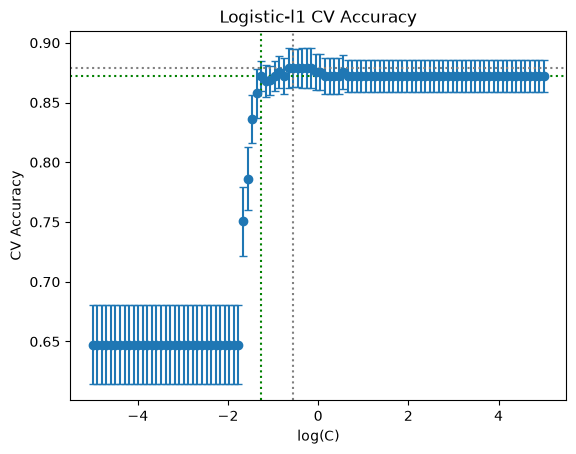

In [21]:
import matplotlib.pyplot as plt
# Plot results of cross-validation
cv_res = logistic_l1_cv

mean_scores = cv_res.cv_results_["mean_test_score"]
se_scores = cv_res.cv_results_["std_test_score"] / np.sqrt(10) # ! very important to divide by sqrt(# folds)
params = cv_res.cv_results_["param_logistic__C"].data

best_index = np.argmax(mean_scores)

one_se_best_param = np.min(
    grid[mean_scores >= mean_scores[best_index] - se_scores[best_index]]
)

one_se_score = mean_scores[grid == one_se_best_param][0]

# just for reference, we also plot the parameter that maximizes the cross-validated accuracy
best_param = cv_res.best_params_["logistic__C"] 
best_score = cv_res.best_score_

plt.errorbar(x=np.log10(grid), y=mean_scores, yerr=se_scores, fmt="o", capsize=3)

plt.axvline(
    np.log10(best_param), ls="dotted", color="grey"
)  # vertical line at the parameter value yielding highest accuracty
plt.axhline(
    best_score, ls="dotted", color="grey"
)  # horizontal line at highest accuracy
plt.axvline(
    np.log10(one_se_best_param), ls="dotted", color="green"
)  # vertical line at the parameter corresponding to 1-se
plt.axhline(
    one_se_score, ls="dotted", color="green"
)  # horizontal line at corresponding to 1-se parameter

plt.title("Logistic-l1 CV Accuracy")
plt.xlabel("log(C)")
plt.ylabel("CV Accuracy")
plt.show()

* Finally, refit the __1-se rule__ model to the whole training dataset, and compute the accuracy on the training and test dataset.

In [22]:
# Finally, refit the __1-se rule__ model to the whole training dataset, and compute the accuracy on the training and test dataset.
pipe_logistic_l1_1se = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(C=one_se_best_param, penalty='l1', solver='saga', tol=0.1, random_state=10))
])
pipe_logistic_l1_1se.fit(X_train, y_train)
train_accuracy_1se = pipe_logistic_l1_1se.score(X_train, y_train)
test_accuracy_1se = pipe_logistic_l1_1se.score(X_test, y_test)

print(f"Train accuracy (1-se): {train_accuracy_1se}")
print(f"Test accuracy (1-se): {test_accuracy_1se}")

Train accuracy (1-se): 0.8790035587188612
Test accuracy (1-se): 0.8


/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/edouarddewaerheijd/unige/machine-learning/TPs/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


* Does this model perform better than the unregularized logistic regression? What are the advantages of this model?

## Problem 2

In [23]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, GridSearchCV

### 2.0 Data import and Cleaning

Import the "Heart" dataset, containing demographic and medical informations about a list of patients. Drop `NA` values, convert the categorical variables into the desired pandas type: "category", and perform any other necessary data cleaning.

In [ ]:
data = pd.read_csv('ionosphere.csv')
print(data.head())


   a01  a02      a03      a04      a05      a06      a07      a08      a09  \
0    1    0  0.99539 -0.05889  0.85243  0.02306  0.83398 -0.37708  1.00000   
1    1    0  1.00000 -0.18829  0.93035 -0.36156 -0.10868 -0.93597  1.00000   
2    1    0  1.00000 -0.03365  1.00000  0.00485  1.00000 -0.12062  0.88965   
3    1    0  1.00000 -0.45161  1.00000  1.00000  0.71216 -1.00000  0.00000   
4    1    0  1.00000 -0.02401  0.94140  0.06531  0.92106 -0.23255  0.77152   

       a10  ...      a26      a27      a28      a29      a30      a31  \
0  0.03760  ... -0.51171  0.41078 -0.46168  0.21266 -0.34090  0.42267   
1 -0.04549  ... -0.26569 -0.20468 -0.18401 -0.19040 -0.11593 -0.16626   
2  0.01198  ... -0.40220  0.58984 -0.22145  0.43100 -0.17365  0.60436   
3  0.00000  ...  0.90695  0.51613  1.00000  1.00000 -0.20099  0.25682   
4 -0.16399  ... -0.65158  0.13290 -0.53206  0.02431 -0.62197 -0.05707   

       a32      a33      a34  class  
0 -0.54487  0.18641 -0.45300      g  
1 -0.06288 -0.13

The response variable that we will try to predict is "AHD", that indicates whether the patient has a heart disease.

Now split the data into the features `X` and the response `y`.

As, sadly, trees in sklearn do not handle categorical features directly, transform `X`'s categorical variables into "dummies". This can be achieved either with panda's `pd.get_dummies(<data>, drop_first=True)` or sklearn's `OneHotEncoder`. Make sure that you keep X in dataframe format, and keep feature/column names.

In [25]:
X = data.drop("class", axis=1)
y = data["class"]

Split the data into train and test. Set random_state=40 and leave 20% of the data out for the test set.

In [27]:
#set seed
# spplit the data into training and test sets 20% test size
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=40, stratify=y)

### 2.1 Unpruned tree

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

Begin by fitting a (unpruned) classification tree to the training data, in order to predict whether each patient potentially has AHD, based on his available demographic and medical information. Use either the Gini index or the entropy as a splitting criterion, as you prefer.

In [29]:
#unpruned decision tree
tree = DecisionTreeClassifier(criterion='gini')
tree.fit(X_train, y_train)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

Now plot the tree using sklearn's `plot_tree` function

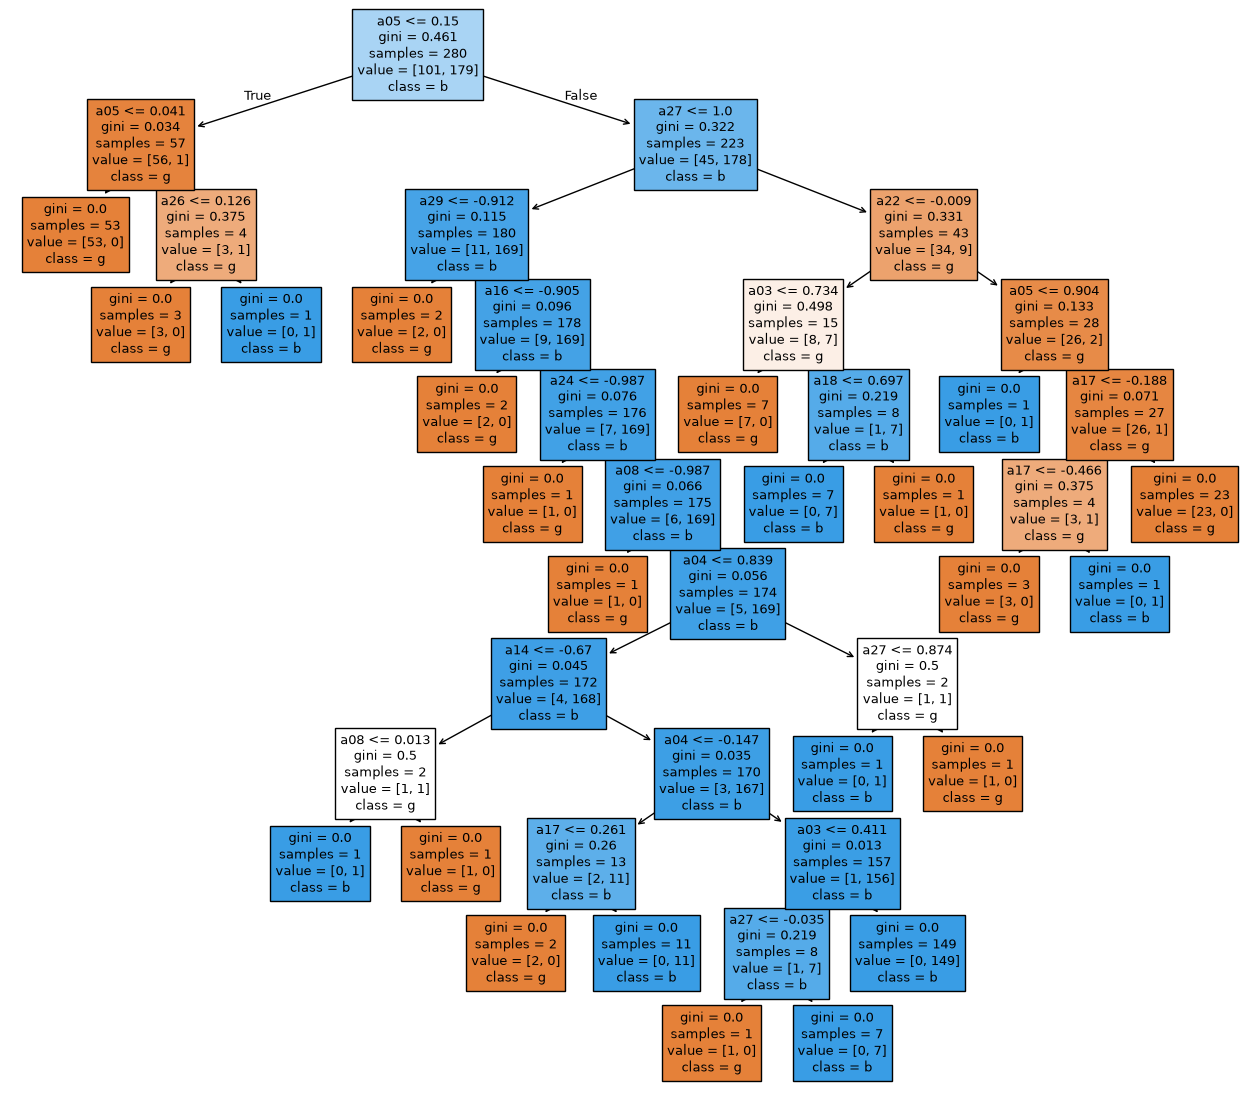

In [30]:
plt.figure(figsize=(16,14))
plot_tree(tree, feature_names=X.columns, class_names=y.unique(), filled=True)
plt.show()

Could you use only this image to predict the "AHD" variable for the observations left out in the test set?

Now check the model's training and test accuracy (or score). What do you observe and why ?

In [31]:
print("Train accuracy:", tree.score(X_train, y_train))
print("Test accuracy:", tree.score(X_test, y_test))


Train accuracy: 1.0
Test accuracy: 0.8450704225352113


### 2.2. Cost-complexity pruning

Remember that the flexibility of a decision tree can be tuned by pruning it via cost-complexity pruning.

Use cross-validation to select the best cost-complexity hyper-parameter $\alpha$ value. Then, plot the tree coresponding to the best $\alpha$ value.

In [41]:
#cost complexity pruning
path = tree.cost_complexity_pruning_path(X_train, y_train)

In [42]:
#use cross validation to find the best alpha parameter for pruning the tree. Use 10 folds and random_state=919. Name the object `folds`.
folds = KFold(n_splits=10, shuffle=True, random_state=919)
#ccp_alphas = path.ccp_alphas[:-1]   # drop the last alpha, which prunes the tree down to just the root

In [46]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=919),
    param_grid={"ccp_alpha": ccp_alphas},
    cv=folds,
    scoring="accuracy",
)
grid.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...dom_state=919)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': array([0. ..., 0.1319659 ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbos

In [47]:
best_alpha = grid.best_params_["ccp_alpha"]
best_alpha


np.float64(0.005111948688985811)

In [49]:
#check acuracy of the pruned tree on the training and test sets
pruned_tree = DecisionTreeClassifier(random_state=919, ccp_alpha=best_alpha)
pruned_tree.fit(X_train, y_train)

train_accuracy = pruned_tree.score(X_train, y_train)
test_accuracy = pruned_tree.score(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

Training accuracy: 0.975
Test accuracy: 0.859


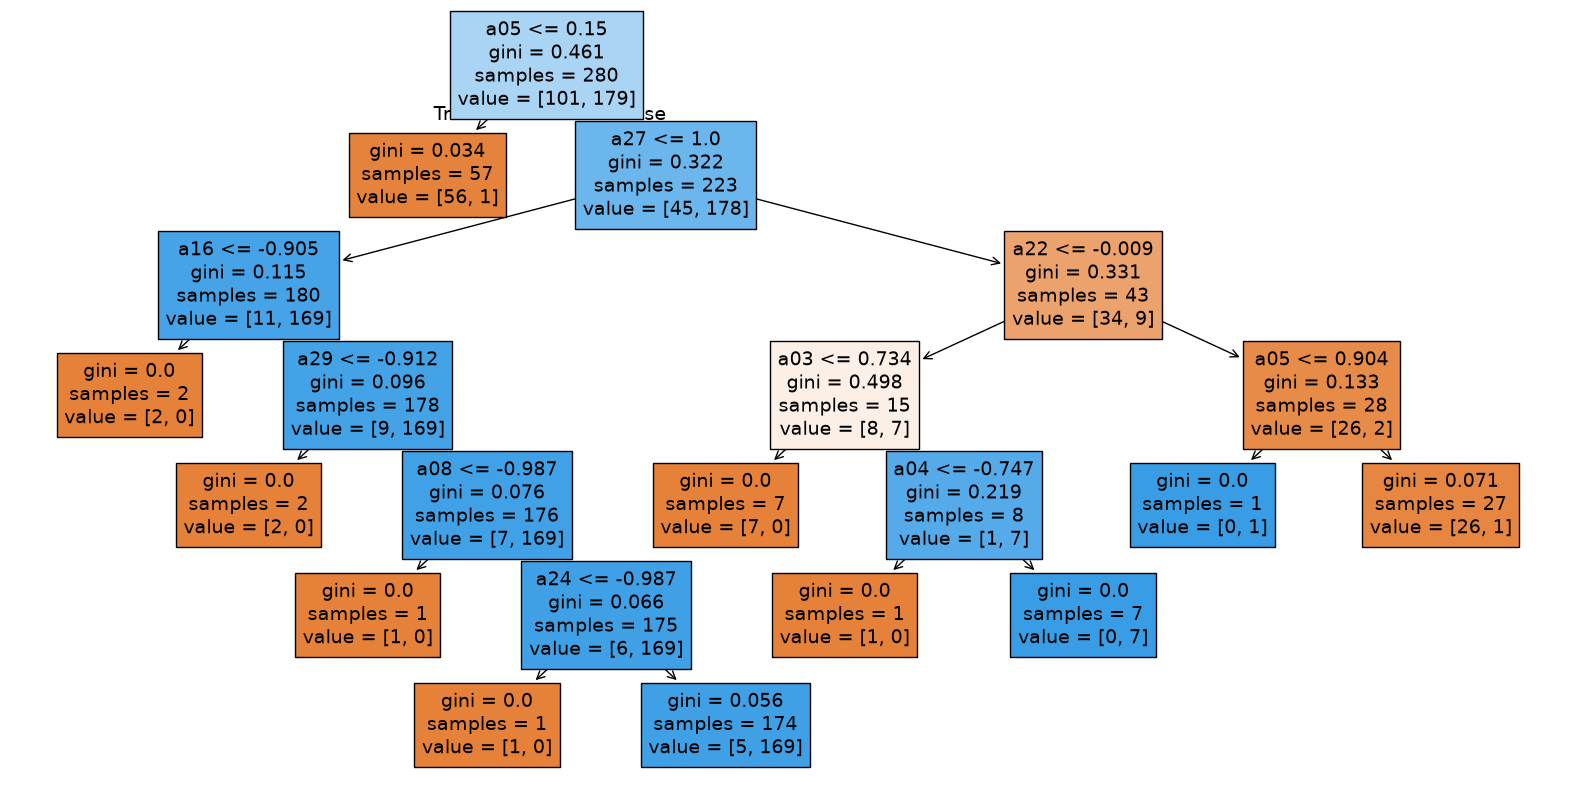

In [48]:
plt.figure(figsize=(20, 10))
plot_tree(grid.best_estimator_, feature_names=X_train.columns, filled=True)
plt.show()

## Problem 3 (not to hand in)

Suppose we have independent observations $(x_1,y_1),\dots, (x_n,y_n)$ from $(X,Y)$ with $x_i \in \mathbb R^p$, and $y_i \in \{0,1\}$,  $i = 1, \dots, n$.
Further assume that the conditional distribution of $Y$ given $X= x$ is Bernoulli with success probability denoted as:
  $$ \mathbb P(Y = 1 \mid X = x) = 1 - \mathbb P(Y = 0 \mid X = x) = \sigma(x^\top \beta),$$
where $\sigma: \mathbb R \to [0, 1]$, and
  $$
  \sigma(a) = \dfrac{e^{a}}{1 + e^{a}}, \quad a\in \mathbb R.
$$
Show that the log-likelihood of the parameter vector $\beta\in\mathbb R^p$ is
  $$\ell(\beta) = \sum_{i=1}^n y_i x_i^\top \beta - \log(1 + e^{x_i^\top \beta}).$$

Suppose we have independent observations $(x_1,y_1),\dots, (x_n,y_n)$ from $(X,Y)$ with $x_i \in \mathbb R^p$, and $y_i \in \{0,1\}$, $i = 1, \dots, n$.

Further assume that the conditional distribution of $Y$ given $X= x$ is Bernoulli with success probability denoted as:

$$ \mathbb P(Y = 1 \mid X = x) = 1 - \mathbb P(Y = 0 \mid X = x) = \sigma(x^\top \beta),$$

where $\sigma: \mathbb R \to [0, 1]$, and

$$

\sigma(a) = \dfrac{e^{a}}{1 + e^{a}}, \quad a\in \mathbb R.

$$

Show that the log-likelihood of the parameter vector $\beta\in\mathbb R^p$ is

$$\ell(\beta) = \sum_{i=1}^n y_i x_i^\top \beta - \log(1 + e^{x_i^\top \beta}).$$

we can start with the fact that likelihood is defined as:
$$
\ell(\beta)=\log L(\beta)=\sum^n_{i=1}\log \mathbb{P}(Y=y_{i}|X=x_{i};\beta)
$$
since we know $\mathbb{P}(Y=1|X=x)=1- \mathbb{P}(Y=0|X=x)=\sigma(x^{\top}\beta)$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}\log(\sigma(x^{\top}_{i}\beta)^{y_{i}}(1-\sigma(x^{\top}_{i}\beta)^{1-y_{i}}))
$$
since $\log(ab)=\log(a)+\log(b)$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}\log(\sigma(x^{\top}_{i}\beta)^{y_{i}})+\log(1-\sigma(x^{\top}_{i}\beta)^{1-y_{i}})
$$
since $\log(a^b)=b\log(a)$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}\log(\sigma(x^{\top}_{i}\beta))+(1-y_{i})\log(
1-\sigma(x^{\top}_{i}\beta))
$$
since $1-\sigma(a) = 1 - \frac{e^a}{1+e^a} \Leftrightarrow \frac{1+ e^a}{1+e^a} -\frac{e^a}{1+e^a}=\frac{1}{1+e^a}$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}\log(\sigma(x^{\top}_{i}\beta))+(1-y_{i})\log\left( \frac{1}{1+e^{x^{\top}_{i}\beta}} \right)
$$
since $\log\left( \frac{a}{b} \right)=\log(a)-\log(b)$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}\log(\sigma(x^{\top}_{i}\beta))+(1-y_{i})(\log(1)-\log(1+e^{x^{\top}_{i}\beta}))
$$
$\log(1)=0$ btw
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}\log(\sigma(x^{\top}_{i}\beta))+(1-y_{i})(-\log(1+e^{x^{\top}_{i}\beta}))
$$
since $\sigma(a)=\frac{e^a}{1+e^a} \Leftrightarrow \log(\sigma(a))=\log\left( \frac{e^a}{1+e^a} \right) \Leftrightarrow \log(\sigma(a))=\log(e^a)-\log(1+e^a)$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}(\log(e^{x^{\top}_{i}\beta})-\log(1+e^{x^{\top}_{i}\beta}))+(1-y_{i})(-\log(1+e^{x^{\top}_{i}\beta}))
$$
distribute
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}\log(e^{x^{\top}_{i}\beta})-y_{i}\log(1+e^{x^{\top}_{i}\beta})-\log(1+e^{x^{\top}_{i}\beta})+y_{i}\log(1+e^{x^{\top}_{i}\beta})
$$
the $y_{i}\log(1+e^{x^{\top}_{i}\beta})$ term cancel out
$$
\Leftrightarrow \ell(\beta)=\sum^n
_{i=1}y_{i}\log(e^{x^{\top}_{i}\beta})-\log(1+e^{x^{\top}_{i}\beta})$$
and since $\log$ here is assumed to be $\ln$ we can say that $\log(e^a)=a$
$$
\Leftrightarrow \ell(\beta)=\sum^n_{i=1}y_{i}x^{\top}_{i}\beta-\log(1+e^{x^{\top}_{i}\beta}) \blacksquare
$$
